#### Document Data Structure

**In LangChain Document**

```python
from langchain.schema import Document
```

Core Components:
- page_content (str)
- metadata (dict)

```python
# Creating a Document

doc = Document(
    page_content= "RAG is a technique ... " ,
    metadata={
        "source" : "chapter1.pdf" ,
        "page" : 5,
        "timestamp" : "2024-01-15"
    }
) 
```

#### LangChain Document Loaders

<h1><b>
PDFLoader
<b></h1>

```python
from langchain.document_loaders import PyPDFLoader
loader = PyPDFLoader("file.pdf")

documents = loader.load()
```

<h1><b>
CSVLoader
<b></h1>

```python
from langchain.document_loaders import CSVLoader
loader = CSVLoader("data.csv")

documents = loader.load()
```

<h1><b>WebBaseLoader<b></h1>

```python
from langchain.document_loaders import WebBaseLoader
loader = WebBaseLoader("https:// ... ")

documents = loader.load()
```

<h1><b>DirectoryLoader<b></h1>

```python
from langchain.document_loaders import DirectoryLoader
loader = DirectoryLoader("./docs")

documents = loader.load()
```

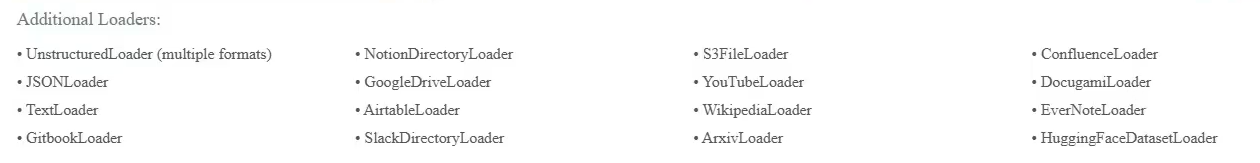

## Data Ingestion

#### Setup

In [3]:
### document structure

from langchain_core.documents import Document

In [4]:
doc=Document(
    page_content="this is the main text content I am using to create RAG",
    metadata={
        "source":"exmaple.txt",
        "pages":1,
        "author":"Naveen Reddu",
        "date_created": "2025-01-01"
    }
)

In [5]:
doc

Document(metadata={'source': 'exmaple.txt', 'pages': 1, 'author': 'Naveen Reddu', 'date_created': '2025-01-01'}, page_content='this is the main text content I am using to create RAG')

In [6]:
## Create a simple txt file
import os
os.makedirs("../data/text_files", exist_ok=True)

In [10]:
sample_texts = {
    "../data/text_files/python_intro.txt":"""Python Programming Introduction

Python is a high-level, interpreted programming language known for its simplicity and readability.
Created by Guido van Rossum and first released in 1991, Python has become one of the most popular programming languages in the world.

Key Features:
- Easy to learn and use
- Extensive standard library
- Cross-platform compatibility
- Strong community support

Python is widely used in web development, data science, artificial intelligence, and automation.'""",




    "../data/text_files/machine_learning.txt": """Machine Learning Basics

Machine learning is a subset of artificial intelligence that enables systems to learn and improve from experience without being explicitly programmed. It focuses on developing computer programs that can access data and use it .to learn for themselves.

Types of Machine Learning:
1. Supervised Learning: Learning with labeled data
2. Unsupervised Learning: Finding patterns in unlabeled data
3. Reinforcement Learning: Learning through rewards and penalties

Applications include image recognition, speech processing, and recommendation systems

"""
}

for filepath,content in sample_texts.items():
    with open(filepath, 'w' ,encoding="utf-8") as f:
        f.write(content)

print("Sample text files created!")


Sample text files created!


#### Text Loader

In [11]:
from langchain_community.document_loaders import TextLoader


loader = TextLoader("../data/text_files/python_intro.txt",encoding='utf-8')
loader.load()

[Document(metadata={'source': '../data/text_files/python_intro.txt'}, page_content="Python Programming Introduction\n\nPython is a high-level, interpreted programming language known for its simplicity and readability.\nCreated by Guido van Rossum and first released in 1991, Python has become one of the most popular programming languages in the world.\n\nKey Features:\n- Easy to learn and use\n- Extensive standard library\n- Cross-platform compatibility\n- Strong community support\n\nPython is widely used in web development, data science, artificial intelligence, and automation.'")]

#### Directory Loader

In [16]:
from langchain_community.document_loaders import DirectoryLoader

## load all the text files from the directory
dir_loader=DirectoryLoader(
    "../data/text_files",
    glob="**/*.txt", ## Pattern to match files
    loader_cls= TextLoader, ##loader class to use
    loader_kwargs={'encoding': 'utf-8'},
    show_progress=False
)

documents = dir_loader.load()
print(documents)

[Document(metadata={'source': '..\\data\\text_files\\machine_learning.txt'}, page_content='Machine Learning Basics\n\nMachine learning is a subset of artificial intelligence that enables systems to learn and improve from experience without being explicitly programmed. It focuses on developing computer programs that can access data and use it .to learn for themselves.\n\nTypes of Machine Learning:\n1. Supervised Learning: Learning with labeled data\n2. Unsupervised Learning: Finding patterns in unlabeled data\n3. Reinforcement Learning: Learning through rewards and penalties\n\nApplications include image recognition, speech processing, and recommendation systems\n\n'), Document(metadata={'source': '..\\data\\text_files\\python_intro.txt'}, page_content="Python Programming Introduction\n\nPython is a high-level, interpreted programming language known for its simplicity and readability.\nCreated by Guido van Rossum and first released in 1991, Python has become one of the most popular prog

In [17]:
from langchain_community.document_loaders import DirectoryLoader
from langchain_community.document_loaders import PyPDFLoader, PyMuPDFLoader

## pdf files
dir_loader=DirectoryLoader(
    "../data/pdf",
    glob="**/*.pdf", 
    loader_cls= PyMuPDFLoader,
    show_progress=False
)

documents = dir_loader.load()
print(documents)

[Document(metadata={'producer': 'pdfTeX-1.40.17', 'creator': 'LaTeX with hyperref package', 'creationdate': '2017-06-13T00:21:17+00:00', 'source': '..\\data\\pdf\\attention.pdf', 'file_path': '..\\data\\pdf\\attention.pdf', 'total_pages': 15, 'format': 'PDF 1.5', 'title': '', 'author': '', 'subject': '', 'keywords': '', 'moddate': '2017-06-13T00:21:17+00:00', 'trapped': '', 'modDate': 'D:20170613002117Z', 'creationDate': 'D:20170613002117Z', 'page': 0}, page_content='Attention Is All You Need\nAshish Vaswani∗\nGoogle Brain\navaswani@google.com\nNoam Shazeer∗\nGoogle Brain\nnoam@google.com\nNiki Parmar∗\nGoogle Research\nnikip@google.com\nJakob Uszkoreit∗\nGoogle Research\nusz@google.com\nLlion Jones∗\nGoogle Research\nllion@google.com\nAidan N. Gomez∗†\nUniversity of Toronto\naidan@cs.toronto.edu\nŁukasz Kaiser∗\nGoogle Brain\nlukaszkaiser@google.com\nIllia Polosukhin∗\nillia.polosukhin@gmail.com\nAbstract\nThe dominant sequence transduction models are based on complex recurrent or\nco